# Individual Data Analysis & Cleaning — Thisara (Candidate Master Pipeline)

**Member:** Thisara (Data Engineering Lead)  
**Module:** CI7340 Applied Data Programming — Group 17  
**Allowed Libraries Strictly Used:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `geopandas`  
**Purpose:** Complete, reproducible data quality audit, Python missing-data method comparison, spatial verification with GeoPandas, feature engineering, and candidate cleaned dataset export (`cleaned_candidate_thisara.csv.gz`) for our **3-Member Cleaning Review & Merge** with Sachithra and Kavindu.

### Pipeline Roadmap
1. **Raw Ingestion & Schema Audit** (`508,106` rows × `30` columns)
2. **Missingness, Duplicates & NIBRS Granularity Audit** (`Incident ID` vs. Offence Row vs. `Victims`)
3. **Temporal Audit & Feature Engineering** (Partial years, CAD cutoff, `End < Start`, `Dispatch < Start`, `00:00:00` midnight spike)
4. **Categorical, Taxonomy & Domain Trap Cleaning** (`NIBRS 90Z`, `Not a Crime`, `State` numeric bleed, `Police District Name`, `Place` macro-categories)
5. **Spatial Audit & GeoPandas Verification** (`(0, 0)` Null Island sentinel handling, `EPSG:4326` GeoDataFrame, `EPSG:26918` projection & district spatial map)
6. **Quantitative Comparison of 3 Cleaning Strategies** (Naive Listwise Drop vs. Partial Drop vs. Domain-Aware Flagging & Targeted Imputation)
7. **Analytical Datasets (Offence-Level & Incident-Level) + Candidate Export & Review Scorecard**


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import geopandas as gpd

sys.path.append(str(Path("..").resolve()))
from utils.viz_style import apply_style, PALETTE, RAW_DATA_PATH, REPO_ROOT

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("Raw dataset path:", RAW_DATA_PATH)
print("Libraries loaded: numpy, pandas, matplotlib, seaborn, geopandas")


Raw dataset path: /mnt/D/DOCUMENTS/MSC/Material/Applied Data Programming/Group-Assignment/ADP-CW01-Group-17/data/raw/dataset_coursework1.csv
Libraries loaded: numpy, pandas, matplotlib, seaborn, geopandas


## 1. Raw Dataset Ingestion & Initial Schema Audit


In [2]:
df_raw = pd.read_csv(RAW_DATA_PATH, low_memory=False)
n_raw_rows, n_raw_cols = df_raw.shape
mem_mb = df_raw.memory_usage(deep=True).sum() / 1e6

print(f"Raw Shape:  {n_raw_rows:,} rows x {n_raw_cols} columns")
print(f"Memory:     {mem_mb:.1f} MB")
display(df_raw.head(3))


Raw Shape:  508,106 rows x 30 columns
Memory:     243.0 MB


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,Crime Name3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,"20,904.0000",MCPD,Government Building,I,3I1,148,"1,000.0000",NaN,MILESTONE,NaN,DR,39.0457,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - BUSINESS,GERMANTOWN,13000 BLK MIDDLEBROOK RD,GERMANTOWN,MD,"20,874.0000",MCPD,Retail - Drug Store/Pharmacy,N,5N1,702,"13,000.0000",NaN,MIDDLEBROOK,NaN,RD,39.1814,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,POLICE INFORMATION,SILVER SPRING,1000 BLK MILESTONE DR,SILVER SPRING,MD,"20,904.0000",MCPD,Residence - Other,I,3I1,148,"1,000.0000",NaN,MILESTONE,NaN,DR,39.0457,-76.9920,3D,"(39.0457, -76.992)"


## 2. Missing Values, Duplicates & NIBRS Granularity Audit


In [3]:
# Comprehensive column-level audit table
missing_audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

display(missing_audit)

# Exact duplicate check & NIBRS Incident vs Offence vs Victim granularity
exact_dupes = int(df_raw.duplicated().sum())
n_incidents = int(df_raw["Incident ID"].nunique())
n_cr = int(df_raw["CR Number"].nunique())
off_per_inc = df_raw.groupby("Incident ID").size()
multi_off_inc = int((off_per_inc > 1).sum())

print(f"Exact duplicate rows:     {exact_dupes:,} ({exact_dupes / n_raw_rows * 100:.4f}%)")
print(f"Total offence rows:       {n_raw_rows:,}")
print(f"Unique Incident IDs:      {n_incidents:,} (avg {n_raw_rows / n_incidents:.4f} offences/incident)")
print(f"Unique CR Numbers:        {n_cr:,}")
print(f"Multi-offence incidents:  {multi_off_inc:,} ({multi_off_inc / n_incidents * 100:.2f}% of incidents; max = {off_per_inc.max()})")
print(f"Total Victim-Offence sum: {int(df_raw['Victims'].sum()):,} (max victims in 1 row = {int(df_raw['Victims'].max())})")


,dtype,non_null,missing_count,missing_pct,n_unique
Street Suffix,str,6930,501176,98.6400,6
Street Prefix,str,22561,485545,95.5600,4
End_Date_Time,str,225662,282444,55.5900,157941
Dispatch Date / Time,str,434701,73405,14.4500,397963
Block Address,str,468302,39804,7.8300,23491
Address Number,float64,468445,39661,7.8100,441
State,str,498597,9509,1.8700,12
Zip Code,float64,504632,3474,0.6800,206
Street Type,str,506250,1856,0.3700,35
Police District Name,str,506564,1542,0.3000,8


Exact duplicate rows:     0 (0.0000%)
Total offence rows:       508,106
Unique Incident IDs:      467,601 (avg 1.0866 offences/incident)
Unique CR Numbers:        467,534
Multi-offence incidents:  33,749 (7.22% of incidents; max = 9)
Total Victim-Offence sum: 519,199 (max victims in 1 row = 22)


## 3. Temporal Quality Audit & Cleaning
We parse all three datetime columns, quantify exact chronology/boundary defects, preserve every valid crime row by flagging impossible values rather than dropping them, and engineer clean temporal features.


In [4]:
df = df_raw.drop_duplicates().copy()
dt_cols = ["Dispatch Date / Time", "Start_Date_Time", "End_Date_Time"]
for col in dt_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

for col in dt_cols:
    print(f"{col:22s} | min={df[col].min()} | max={df[col].max()} | nulls={df[col].isna().sum():,} ({df[col].isna().mean()*100:.2f}%)")

# Quantify temporal anomalies
after_brief_cutoff = df["Start_Date_Time"] > "2026-09-10 23:59:59"
invalid_end_mask = df["End_Date_Time"].notna() & (df["End_Date_Time"] < df["Start_Date_Time"])
neg_dispatch_mask = df["Dispatch Date / Time"].notna() & (df["Dispatch Date / Time"] < df["Start_Date_Time"])
exact_midnight_mask = (
    (df["Start_Date_Time"].dt.hour == 0)
    & (df["Start_Date_Time"].dt.minute == 0)
    & (df["Start_Date_Time"].dt.second == 0)
)
hour0_total = (df["Start_Date_Time"].dt.hour == 0).sum()

print("\n--- Temporal Anomaly Quantification ---")
print(f"After brief cutoff (2026-09-10):   {after_brief_cutoff.sum():,} ({after_brief_cutoff.mean()*100:.3f}%)")
print(f"End_Date_Time < Start_Date_Time:   {invalid_end_mask.sum():,} ({invalid_end_mask.mean()*100:.2f}%)")
print(f"Dispatch < Start_Date_Time:        {neg_dispatch_mask.sum():,} ({neg_dispatch_mask.mean()*100:.2f}%)")
print(f"Exact 00:00:00 midnight defaults:  {exact_midnight_mask.sum():,} ({exact_midnight_mask.sum()/hour0_total*100:.1f}% of all Hour-0 records)")

# Flag & clean impossible timestamps without discarding valid crime rows
df["Is_Invalid_End_Time"] = invalid_end_mask
df["Is_Negative_Dispatch_Lag"] = neg_dispatch_mask
df["Is_Midnight_Default"] = exact_midnight_mask
df["Has_End_Time"] = df["End_Date_Time"].notna() & (~invalid_end_mask)
df["Has_Dispatch_Time"] = df["Dispatch Date / Time"].notna()

# Nullify impossible End_Date_Time values so duration stats are uncorrupted
df.loc[invalid_end_mask, "End_Date_Time"] = pd.NaT

# Feature engineering: temporal dimensions
df["Year"] = df["Start_Date_Time"].dt.year
df["Month"] = df["Start_Date_Time"].dt.month
df["Month_Name"] = df["Start_Date_Time"].dt.month_name().str.slice(0, 3)
df["DayOfWeek"] = df["Start_Date_Time"].dt.day_name()
df["Is_Weekend"] = df["Start_Date_Time"].dt.dayofweek >= 5
df["Hour"] = df["Start_Date_Time"].dt.hour
df["Is_Full_Year"] = df["Year"].between(2017, 2025)

df["Time_Period"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night (00-05)", "Morning (06-11)", "Afternoon (12-17)", "Evening (18-23)"],
)

# Valid positive duration & dispatch lag (in hours)
df["Duration_Hours"] = (df["End_Date_Time"] - df["Start_Date_Time"]).dt.total_seconds() / 3600.0
raw_dispatch_lag = (df["Dispatch Date / Time"] - df["Start_Date_Time"]).dt.total_seconds() / 3600.0
df["Dispatch_Lag_Hours"] = np.where(neg_dispatch_mask, np.nan, raw_dispatch_lag)

print("\nValid Dispatch_Lag_Hours summary (hours):")
display(df["Dispatch_Lag_Hours"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]))


Dispatch Date / Time   | min=2017-04-02 07:37:54 | max=2026-09-14 19:46:02 | nulls=73,405 (14.45%)
Start_Date_Time        | min=2016-07-01 00:00:00 | max=2026-09-14 20:44:00 | nulls=0 (0.00%)
End_Date_Time          | min=2016-07-01 00:00:00 | max=2026-09-14 19:00:00 | nulls=282,444 (55.59%)

--- Temporal Anomaly Quantification ---
After brief cutoff (2026-09-10):   228 (0.045%)
End_Date_Time < Start_Date_Time:   8,418 (1.66%)
Dispatch < Start_Date_Time:        29,165 (5.74%)
Exact 00:00:00 midnight defaults:  21,760 (59.1% of all Hour-0 records)

Valid Dispatch_Lag_Hours summary (hours):


/tmp/ipykernel_17888/198592652.py:41: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["Is_Weekend"] = df["Start_Date_Time"].dt.dayofweek >= 5


count   405,536.0000
mean        220.6315
std       1,713.1028
min           0.0000
25%           0.0092
50%           0.1686
75%          17.8367
90%         142.8008
99%       4,894.3113
max      83,898.5281
Name: Dispatch_Lag_Hours, dtype: float64

## 4. Categorical, NIBRS Taxonomy & Domain-Trap Cleaning
Here we clean string whitespace/casing, fix `State` numeric bleed, align `Police District Name` nulls with `Police District Number`, group `Place` into macro-premise categories, and engineer critical NIBRS domain flags (`NIBRS_Group` and `Is_Substantive_Crime`).


In [5]:
# 1. Strip whitespace across all string columns
obj_cols = df.select_dtypes(include="object").columns
for col in obj_cols:
    df[col] = df[col].str.strip()

# 2. Align Police District Name nulls (1,542 rows) to UNKNOWN (matching Police District Number == 'Unknown')
dist_nulls_before = df["Police District Name"].isna().sum()
df["Police District Name"] = df["Police District Name"].fillna("UNKNOWN").str.upper()
print(f"Police District Name nulls imputed to 'UNKNOWN': {dist_nulls_before:,}")

# 3. Clean Agency anomaly ('P' -> 3 rows)
agency_p_count = (df["Agency"] == "P").sum()
df["Agency"] = df["Agency"].replace({"P": "OTHR"})
print(f"Agency code 'P' consolidated into 'OTHR': {agency_p_count:,} rows")

# 4. Clean City & Zip Code
df["City_Clean"] = df["City"].fillna("UNKNOWN").str.upper()
df["Zip_Code_Clean"] = df["Zip Code"].astype(str).str.extract(r"(\d{5})", expand=False)
valid_moco_zip = df["Zip_Code_Clean"].between("20812", "20916")
print(f"Valid 5-digit Montgomery County ZIPs (20812-20916): {valid_moco_zip.sum():,} ({valid_moco_zip.mean()*100:.2f}%)")

# 5. Clean State numeric bleed ('16', '7', '17') & spatially impute MD where coords are inside Montgomery County
state_upper = df["State"].str.upper()
numeric_state_mask = state_upper.str.fullmatch(r"\d+", na=False)
print(f"Numeric noise rows in State ('16', '7', '17'): {numeric_state_mask.sum():,}")

df["State_Clean"] = state_upper.mask(numeric_state_mask, np.nan)
in_moco_bbox = df["Latitude"].between(38.9, 39.4) & df["Longitude"].between(-77.6, -76.8)
state_imputed_mask = df["State_Clean"].isna() & in_moco_bbox
df.loc[state_imputed_mask, "State_Clean"] = "MD"
df["State_Clean"] = df["State_Clean"].fillna("UNKNOWN")
print(f"State values recovered as 'MD' via spatial bounding box: {state_imputed_mask.sum():,}")
print("Cleaned State distribution (top 6):")
print(df["State_Clean"].value_counts().head(6))

# 6. NIBRS Domain Flags: Group A vs Group B, and Substantive Crime vs Non-Criminal Service Workload
df["NIBRS_Group"] = np.where(df["NIBRS Code"].str.startswith("90"), "Group B", "Group A")

non_criminal_90z = {
    "POLICE INFORMATION",
    "MENTAL ILLNESS - EMERGENCY PETITION",
    "MENTAL ILLNESS",
    "LOST PROPERTY",
    "SUDDEN DEATH",
    "MISSING PERSON",
    "RECOVERED PROPERTY - MONT CO.",
    "RECOVERED PROPERTY - OTHER",
}
is_non_criminal_service = (
    (df["Crime Name1"] == "Crime Against Not a Crime")
    | ((df["NIBRS Code"] == "90Z") & (df["Crime Name3"].isin(non_criminal_90z)))
)
df["Is_Substantive_Crime"] = ~is_non_criminal_service

print("\n--- Substantive Crime vs. Non-Criminal Service Workload ---")
print(f"Substantive Criminal Offences: {df['Is_Substantive_Crime'].sum():,} ({df['Is_Substantive_Crime'].mean()*100:.2f}%)")
print(f"Non-Criminal / Service Calls:  {(~df['Is_Substantive_Crime']).sum():,} ({(~df['Is_Substantive_Crime']).mean()*100:.2f}%)")

# 7. Macro Premise Grouping from 100 raw Place values
def map_place_category(val: str) -> str:
    if pd.isna(val):
        return "Other / Unknown"
    v = val.lower()
    if "residence" in v or "apartment" in v or "house" in v or "driveway" in v:
        return "Residential"
    if "street" in v or "highway" in v or "alley" in v or "sidewalk" in v:
        return "Street / Roadway"
    if "parking" in v or "garage" in v:
        return "Parking / Garage"
    if "retail" in v or "store" in v or "grocery" in v or "restaurant" in v or "bar" in v or "bank" in v or "gas" in v or "commercial" in v or "hotel" in v or "mall" in v:
        return "Retail / Commercial"
    if "school" in v or "government" in v or "hospital" in v or "church" in v or "park" in v or "metro" in v or "library" in v:
        return "Public / Institutional"
    return "Other / Unknown"

df["Place_Category"] = df["Place"].apply(map_place_category)
print("\nMacro Place_Category distribution:")
print(df["Place_Category"].value_counts())


/tmp/ipykernel_17888/2844193216.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes(include="object").columns


Police District Name nulls imputed to 'UNKNOWN': 1,542
Agency code 'P' consolidated into 'OTHR': 3 rows


Valid 5-digit Montgomery County ZIPs (20812-20916): 503,821 (99.16%)
Numeric noise rows in State ('16', '7', '17'): 228
State values recovered as 'MD' via spatial bounding box: 9,164
Cleaned State distribution (top 6):
State_Clean
MD         507394
UNKNOWN       573
DC            121
VA             12
ME              2
MS              2
Name: count, dtype: int64

--- Substantive Crime vs. Non-Criminal Service Workload ---
Substantive Criminal Offences: 402,311 (79.18%)
Non-Criminal / Service Calls:  105,795 (20.82%)



Macro Place_Category distribution:
Place_Category
Residential               157876
Street / Roadway          106287
Retail / Commercial        91930
Parking / Garage           67227
Other / Unknown            55001
Public / Institutional     29785
Name: count, dtype: int64


## 5. Spatial Audit & GeoPandas Verification
We detect the `24,648` (`4.85%`) `(0.0, 0.0)` Null Island sentinel coordinates, convert them to `NaN` (preserving the crime rows!), build a `geopandas.GeoDataFrame` (`EPSG:4326`), project to UTM Zone 18N (`EPSG:26918`) to compute metric distances from Montgomery County's geographic centre, and verify spatial integrity visually.


Valid Montgomery County coords: 483,458 (95.15%)
Sentinel (0, 0) -> NaN:         24,648 (4.85%)
GeoDataFrame CRS: EPSG:4326


WGS84 Bounding Box (minx, miny, maxx, maxy): [-77.5167  38.9384 -76.9053  39.3512]


Distance from county crime median centre (km):


count   483,458.0000
mean         10.3169
std           5.0262
min           0.0554
25%           6.4822
50%          10.6405
75%          13.1763
max          36.3595
Name: Dist_From_Center_Km, dtype: float64

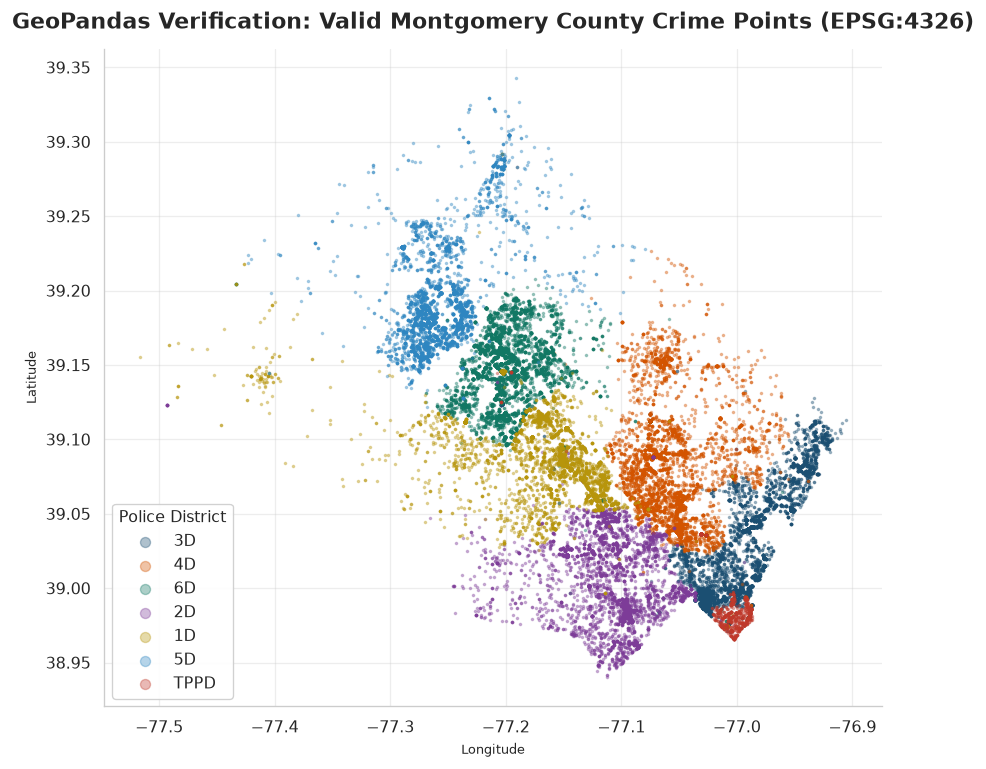

In [6]:
# 1. Flag and nullify (0, 0) Null Island sentinel coordinates (DO NOT drop rows!)
zero_coord_mask = (df["Latitude"] == 0) | (df["Longitude"] == 0)
df["Has_Valid_Coords"] = (~zero_coord_mask) & df["Latitude"].between(38.9, 39.4) & df["Longitude"].between(-77.6, -76.8)
df.loc[~df["Has_Valid_Coords"], ["Latitude", "Longitude"]] = np.nan

print(f"Valid Montgomery County coords: {df['Has_Valid_Coords'].sum():,} ({df['Has_Valid_Coords'].mean()*100:.2f}%)")
print(f"Sentinel (0, 0) -> NaN:         {zero_coord_mask.sum():,} ({zero_coord_mask.mean()*100:.2f}%)")

# 2. Construct GeoPandas GeoDataFrame on valid coordinates (WGS84 -> UTM 18N metric projection)
valid_geo = df.loc[df["Has_Valid_Coords"], ["Incident ID", "Police District Number", "Crime Name1", "Latitude", "Longitude"]].copy()
gdf = gpd.GeoDataFrame(
    valid_geo,
    geometry=gpd.points_from_xy(valid_geo["Longitude"], valid_geo["Latitude"]),
    crs="EPSG:4326",
)
print("GeoDataFrame CRS:", gdf.crs)
print("WGS84 Bounding Box (minx, miny, maxx, maxy):", np.round(gdf.total_bounds, 4))

# Project to EPSG:26918 (NAD83 / UTM zone 18N, metres) to compute distance from county median centre
gdf_utm = gdf.to_crs(epsg=26918)
cx, cy = gdf_utm.geometry.x.median(), gdf_utm.geometry.y.median()
dist_km = np.sqrt((gdf_utm.geometry.x - cx) ** 2 + (gdf_utm.geometry.y - cy) ** 2) / 1000.0
df.loc[df["Has_Valid_Coords"], "Dist_From_Center_Km"] = dist_km.values

print("Distance from county crime median centre (km):")
display(df["Dist_From_Center_Km"].describe())

# 3. GeoPandas spatial verification plot (40,000-point stratified visual sample)
fig, ax = plt.subplots(figsize=(9, 6.5))
dist_order = ["3D", "4D", "6D", "2D", "1D", "5D", "TPPD"]
gdf_sample = gdf[gdf["Police District Number"].isin(dist_order)].sample(n=40000, random_state=42)
for d, color in zip(dist_order, PALETTE[:7]):
    sub = gdf_sample[gdf_sample["Police District Number"] == d]
    sub.plot(ax=ax, markersize=1.8, alpha=0.35, color=color, label=d)

ax.set_title("GeoPandas Verification: Valid Montgomery County Crime Points (EPSG:4326)", pad=12)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Police District", markerscale=4.5, loc="lower left", frameon=True)
plt.tight_layout()
plt.show()


## 6. Quantitative Comparison of Missing-Data & Cleaning Strategies
To justify our final cleaning pipeline rigorously (marking rubric *Initial Data Quality Assessment — 15 marks*), we benchmark **three competing strategies** directly in Python:
- **Strategy A (Naive Listwise Deletion):** `df_raw.dropna()` — destroys nearly the entire dataset due to structurally empty `Street Prefix`/`Street Suffix` and `End_Date_Time`.
- **Strategy B (Partial Drop):** Drop sparse address columns + drop rows with missing `Dispatch Date / Time`, `Block Address`, or `(0, 0)` coordinates — introduces severe temporal bias (erases pre-April 2017) and crime-type bias (erases privacy-redacted assaults).
- **Strategy C (Thisara's Recommended Domain-Aware Strategy):** Prune only 4 structurally empty/redundant columns (`Street Prefix`, `Street Suffix`, `Address Number`, `Location`), preserve **100%** of unique crime rows, nullify/flag impossible timestamps and `(0, 0)` coordinates, and recover `State` via spatial bounds.


,Strategy,Rows_Retained,Rows_Lost,Retention_Pct,Key_Tradeoff
0,A: Naive Listwise Drop (dropna),0,508106,0.0000,Catastrophic loss (>99% rows erased due to str...
1,B: Partial Drop (Drop Missing Dispatch/Block/0...,370833,137273,72.9800,Severe bias: deletes pre-Apr 2017 & privacy-re...
2,C: Domain-Aware Flagging & Pruning (Recommended),508106,0,100.0000,Zero unnecessary row loss; all defects flagged...


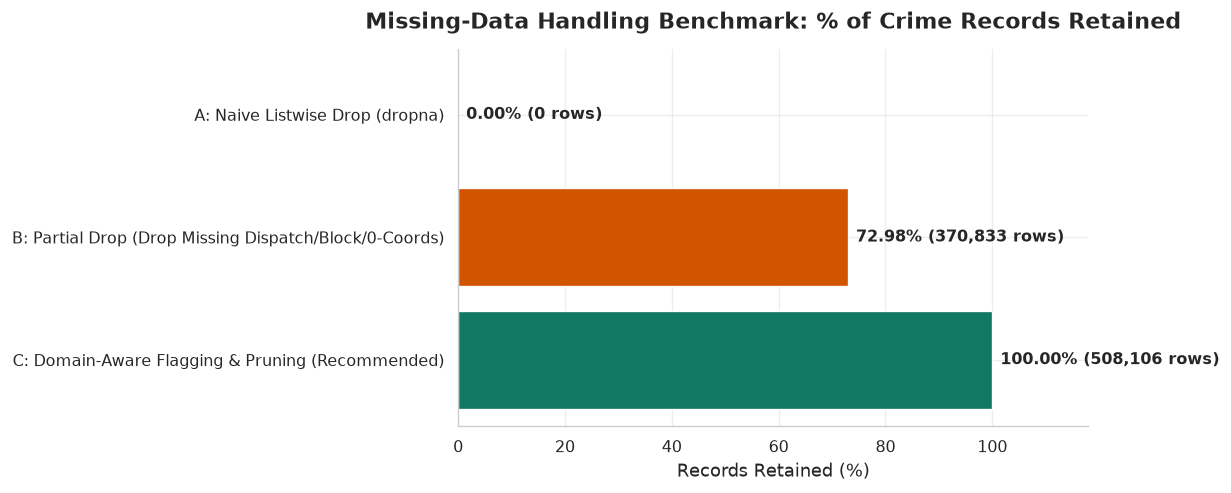

In [7]:
# Strategy A: Naive Listwise Deletion
n_strat_a = len(df_raw.dropna())

# Strategy B: Partial Drop (drop sparse street cols, then drop rows with missing Dispatch, Block Address, or (0,0) coords)
strat_b_df = df_raw.drop(columns=["Street Prefix", "Street Suffix", "End_Date_Time", "Address Number", "Location"])
strat_b_df = strat_b_df.dropna(subset=["Dispatch Date / Time", "Block Address", "Police District Name", "State", "Zip Code"])
strat_b_df = strat_b_df[(strat_b_df["Latitude"] != 0) & (strat_b_df["Longitude"] != 0)]
n_strat_b = len(strat_b_df)

# Strategy C: Domain-Aware Flagging & Targeted Imputation (Thisara's pipeline)
cols_to_drop = ["Street Prefix", "Street Suffix", "Address Number", "Location"]
df_clean = df.drop(columns=cols_to_drop).copy()
n_strat_c = len(df_clean)

comparison = pd.DataFrame({
    "Strategy": [
        "A: Naive Listwise Drop (dropna)",
        "B: Partial Drop (Drop Missing Dispatch/Block/0-Coords)",
        "C: Domain-Aware Flagging & Pruning (Recommended)",
    ],
    "Rows_Retained": [n_strat_a, n_strat_b, n_strat_c],
    "Rows_Lost": [n_raw_rows - n_strat_a, n_raw_rows - n_strat_b, n_raw_rows - n_strat_c],
    "Retention_Pct": [
        round(n_strat_a / n_raw_rows * 100, 2),
        round(n_strat_b / n_raw_rows * 100, 2),
        round(n_strat_c / n_raw_rows * 100, 2),
    ],
    "Key_Tradeoff": [
        "Catastrophic loss (>99% rows erased due to structural nulls)",
        "Severe bias: deletes pre-Apr 2017 & privacy-redacted assaults",
        "Zero unnecessary row loss; all defects flagged for task-specific filtering",
    ],
})
display(comparison)

# Visual comparison chart
fig, ax = plt.subplots(figsize=(10, 4.2))
colors_cmp = [PALETTE[6], PALETTE[1], PALETTE[2]]
bars = ax.barh(comparison["Strategy"][::-1], comparison["Retention_Pct"][::-1], color=colors_cmp[::-1], edgecolor="white")
ax.set_title("Missing-Data Handling Benchmark: % of Crime Records Retained", pad=12)
ax.set_xlabel("Records Retained (%)")
ax.set_xlim(0, 118)
for b, cnt in zip(bars, comparison["Rows_Retained"][::-1]):
    w = b.get_width()
    ax.text(w + 1.5, b.get_y() + b.get_height()/2, f"{w:.2f}% ({cnt:,} rows)", va="center", fontsize=9.5, fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Analytical Datasets (Offence-Level & Incident-Level) + Candidate Export
We construct both the **Offence-Level Cleaned Dataset** (`df_clean`) and an **Incident-Level Aggregated View** (`df_incidents`), export `cleaned_candidate_thisara.csv.gz` (compressed natively via `pandas` with zero extra dependencies), and print a **Team Merge Review Scorecard** for Sachithra and Kavindu.


In [8]:
# 1. Construct Incident-Level Analytical Dataset (467,601 unique incidents)
df_incidents = (
    df_clean.groupby("Incident ID", as_index=False)
    .agg(
        CR_Number=("CR Number", "first"),
        Start_Date_Time=("Start_Date_Time", "min"),
        Year=("Year", "first"),
        Police_District=("Police District Number", "first"),
        Agency=("Agency", "first"),
        Offence_Count=("Offence Code", "size"),
        Total_Victims=("Victims", "sum"),
        Has_Substantive_Crime=("Is_Substantive_Crime", "any"),
        Has_Valid_Coords=("Has_Valid_Coords", "any"),
    )
)
df_incidents["Is_Multi_Offence"] = df_incidents["Offence_Count"] > 1

print(f"Offence-level table:  {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Incident-level table: {df_incidents.shape[0]:,} rows x {df_incidents.shape[1]} columns")
display(df_incidents.head(3))

# 2. Export Candidate Cleaned Dataset (gzip CSV — native pandas, no pyarrow needed)
out_path = REPO_ROOT / "data" / "processed" / "cleaned_candidate_thisara.csv.gz"
out_path.parent.mkdir(parents=True, exist_ok=True)
df_clean.to_csv(out_path, index=False, compression="gzip")
size_mb = out_path.stat().st_size / 1e6

print("\n================ TEAM MERGE REVIEW SCORECARD (THISARA) ================")
print(f"Output file:              {out_path.name} ({size_mb:.2f} MB compressed)")
print(f"Rows retained:            {len(df_clean):,} / {n_raw_rows:,} ({len(df_clean)/n_raw_rows*100:.2f}%)")
print(f"Dropped sparse/dup cols:  {cols_to_drop}")
print(f"Final column count:       {df_clean.shape[1]} (26 retained + engineered features/flags)")
print(f"Unique Incidents:         {len(df_incidents):,} (Multi-offence: {df_incidents['Is_Multi_Offence'].sum():,})")
print(f"Substantive Crimes:       {df_clean['Is_Substantive_Crime'].sum():,} ({df_clean['Is_Substantive_Crime'].mean()*100:.2f}%)")
print(f"Valid GeoPandas Coords:   {df_clean['Has_Valid_Coords'].sum():,} ({df_clean['Has_Valid_Coords'].mean()*100:.2f}%)")
print(f"End < Start flagged:      {df_clean['Is_Invalid_End_Time'].sum():,}")
print(f"Dispatch < Start flagged: {df_clean['Is_Negative_Dispatch_Lag'].sum():,}")
print(f"Midnight 00:00:00 flagged:{df_clean['Is_Midnight_Default'].sum():,}")
print("=======================================================================")


Offence-level table:  508,106 rows x 49 columns
Incident-level table: 467,601 rows x 11 columns


,Incident ID,CR_Number,Start_Date_Time,Year,Police_District,Agency,Offence_Count,Total_Victims,Has_Substantive_Crime,Has_Valid_Coords,Is_Multi_Offence
0,201087096,16033231,2016-07-01 00:22:00,2016,5D,MCPD,1,1,True,True,False
1,201087097,16033232,2016-07-01 00:04:00,2016,4D,MCPD,3,3,True,True,True
2,201087100,16033233,2016-07-01 00:32:00,2016,5D,MCPD,1,1,True,True,False



================ TEAM MERGE REVIEW SCORECARD (THISARA) ================
Output file:              cleaned_candidate_thisara.csv.gz (38.50 MB compressed)
Rows retained:            508,106 / 508,106 (100.00%)
Dropped sparse/dup cols:  ['Street Prefix', 'Street Suffix', 'Address Number', 'Location']
Final column count:       49 (26 retained + engineered features/flags)
Unique Incidents:         467,601 (Multi-offence: 33,749)
Substantive Crimes:       402,311 (79.18%)
Valid GeoPandas Coords:   483,458 (95.15%)
End < Start flagged:      8,418
Dispatch < Start flagged: 29,165
Midnight 00:00:00 flagged:21,760
